<a href="https://colab.research.google.com/github/amahendra/Sequential_Decision_Analytics_Modeling_Course/blob/main/Praktikum_LSTM_Prediksi_Suhu_Jakarta_TensorFlow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum LSTM: Prediksi Suhu Jakarta 1 Jam ke Depan

**Mata kuliah:** Deep Learning — RNN dan Data Sekuensial  
**Framework:** TensorFlow / Keras • **Runtime:** Google Colab CPU (GPU tidak wajib)

**Tujuan:** memanfaatkan 6 jam pengamatan cuaca terakhir (**36 sampel × 10 menit**) untuk memprediksi **suhu udara (`T (degC)`) satu jam setelah pengamatan terakhir**. Kita menggunakan empat fitur: suhu, kelembapan, tekanan udara, dan kecepatan angin.

**Catatan data:** CSV berisi **52.704 baris data sintetis sepanjang 2024**, bukan catatan observasi BMKG. Nilai suhu dan kelembapan dirancang menyerupai kondisi tropis Jakarta, dengan acuan rerata bulanan BMKG Kemayoran tahun 2024 yang dipublikasikan BPS. Data bersifat simulasi untuk pembelajaran, **tidak boleh diklaim sebagai pengukuran nyata**.

**Cara menjalankan:** Upload CSV ke folder `/content/sample_data/` menggunakan panel Files Colab, lalu klik **Runtime → Run all**. Jalankan dari awal jika mengubah pengaturan eksperimen.

**Alur:** CSV → visualisasi → split berdasarkan waktu → normalisasi tanpa data leakage → window sekuens → LSTM → grafik training → testing dan baseline → prediksi.

## Cell 1 — Import library
Memuat TensorFlow untuk membangun LSTM, pandas/numpy untuk data, matplotlib untuk grafik, dan scikit-learn untuk normalisasi serta evaluasi. Seed membuat eksperimen lebih mudah direproduksi.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)  # Agar hasil lebih konsisten
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Cell 2 — Membaca CSV
Membaca file yang di-upload ke `sample_data`, mengurutkan berdasarkan waktu, dan memastikan tidak ada waktu duplikat atau data kosong. Kolom `Date Time` adalah indeks waktu, bukan fitur numerik mentah.

In [ ]:
PATH = "/content/sample_data/Dataset_Cuaca_Jakarta_Sintetis_2024_10Menit.csv"
df = pd.read_csv(PATH, parse_dates=["Date Time"])
df = df.sort_values("Date Time").reset_index(drop=True)

FITUR = ["T (degC)", "rh (%)", "p (hPa)", "wv (m/s)"]
assert not df["Date Time"].duplicated().any(), "Ada waktu duplikat"
assert not df[FITUR].isna().any().any(), "Ada nilai kosong"
print("Ukuran dataset:", df.shape)
display(df.head())
display(df[FITUR].describe().round(2))

Ukuran dataset: (52704, 15)


,Date Time,T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (hPa),VPact (hPa),VPdef (hPa),sh (g/kg),H2OC (mmol/mol),p (hPa),rho (kg/m3),wv (m/s),max. wv (m/s),wd (deg)
0,2024-01-01 00:00:00,26.39,299.69,24.02,86.8,34.41,29.87,4.53,18.59,30.46,1010.64,1.175,0.51,1.88,233.8
1,2024-01-01 00:10:00,26.25,299.55,24.35,89.3,34.11,30.46,3.64,18.97,31.09,1010.19,1.175,1.42,1.97,170.2
2,2024-01-01 00:20:00,26.22,299.52,24.34,89.4,34.05,30.45,3.60,18.96,31.07,1010.40,1.176,0.55,1.58,96.3
3,2024-01-01 00:30:00,26.27,299.57,24.92,92.3,34.15,31.52,2.63,19.63,32.20,1010.65,1.176,1.00,1.94,348.5
4,2024-01-01 00:40:00,26.22,299.52,24.76,91.7,34.06,31.22,2.83,19.45,31.88,1010.56,1.176,0.14,1.97,236.1


,T (degC),rh (%),p (hPa),wv (m/s)
count,52704.00,52704.00,52704.00,52704.00
mean,28.90,78.25,1009.31,1.19
std,2.59,11.18,1.05,0.78
min,23.20,47.40,1006.64,0.00
25%,26.75,68.50,1008.55,0.62
50%,28.56,79.10,1009.31,1.04
75%,31.07,87.90,1010.08,1.59
max,36.33,98.00,1011.91,7.00


## Cell 3 — Melihat pola suhu
Plot satu minggu pertama. Perhatikan siklus siang–malam dan suhu siang yang tinggi. **Diskusi:** apakah suhu pada pukul 14.00 biasanya lebih tinggi dibanding dini hari?

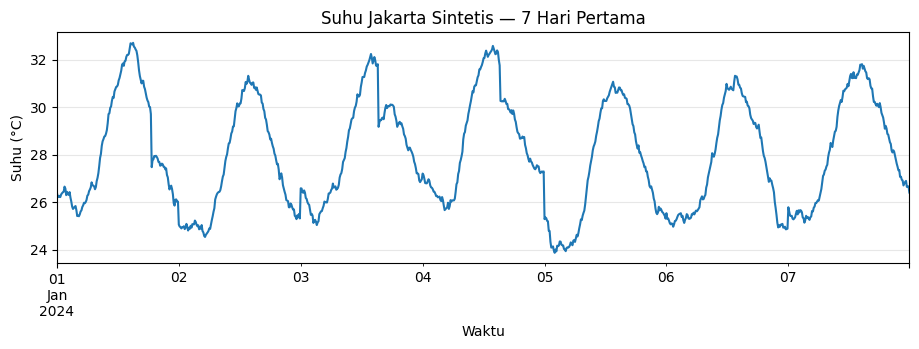

In [ ]:
df.iloc[:7*24*6].plot(x="Date Time", y="T (degC)", figsize=(11, 3), legend=False)
plt.title("Suhu Jakarta Sintetis — 7 Hari Pertama")
plt.ylabel("Suhu (°C)")
plt.xlabel("Waktu")
plt.grid(alpha=0.3)
plt.show()

## Cell 4 — Memisahkan data secara kronologis
70% awal untuk **training**, 15% berikutnya untuk **validation**, dan 15% terakhir untuk **testing**. Ini penting: untuk time-series, **jangan mengacak urutan waktu**. `StandardScaler` dipelajari **hanya pada data training** agar data masa depan tidak bocor ke proses belajar.

In [ ]:
n = len(df)
batas_train, batas_val = int(n*0.70), int(n*0.85)

scaler = StandardScaler()
scaler.fit(df.loc[:batas_train-1, FITUR])  # Fit hanya data training
X_all = scaler.transform(df[FITUR]).astype("float32")

print("Training:", batas_train, "baris")
print("Validation:", batas_val-batas_train, "baris")
print("Testing:", n-batas_val, "baris")

Training: 36892 baris
Validation: 7906 baris
Testing: 7906 baris


## Cell 5 — Menyusun data menjadi sekuens (window)
LSTM menerima tensor `(jumlah_contoh, 36, 4)`: **36 langkah waktu**, masing-masing berisi **4 fitur**. Target adalah suhu **6 langkah setelah observasi terakhir** (1 jam). `X` dan `y` tetap diurutkan; sampel validation/testing boleh memakai **riwayat** dari periode sebelumnya, tetapi targetnya tidak melintasi batas split.

Ubah `WINDOW` atau `HORIZON` untuk eksperimen.

In [ ]:
WINDOW = 36   # 6 jam riwayat (36 x 10 menit)
HORIZON = 6   # Prediksi 1 jam ke depan

def buat_window(data, awal_target, akhir_target):
    X, y, posisi = [], [], []
    # Target berada pada baris t, input terakhir berada pada t-HORIZON
    for t in range(max(awal_target, WINDOW + HORIZON - 1), akhir_target):
        akhir_input = t - HORIZON + 1
        X.append(data[akhir_input-WINDOW:akhir_input])
        y.append(data[t, 0])  # Kolom pertama = suhu yang sudah dinormalisasi
        posisi.append(t)
    return np.asarray(X, dtype="float32"), np.asarray(y, dtype="float32"), np.array(posisi)

X_train, y_train, i_train = buat_window(X_all, 0, batas_train)
X_val, y_val, i_val = buat_window(X_all, batas_train, batas_val)
X_test, y_test, i_test = buat_window(X_all, batas_val, n)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:", X_val.shape, "| X_test:", X_test.shape)

X_train: (36851, 36, 4) | y_train: (36851,)
X_val: (7906, 36, 4) | X_test: (7906, 36, 4)


## Cell 6 — Membuat model LSTM
`LSTM(16)` mempelajari perubahan cuaca secara berurutan. `Dense(1)` menghasilkan **satu angka suhu**, sehingga ini adalah **regresi**, bukan klasifikasi. `Adam` memperbarui bobot model; `MSE` menghukum kesalahan prediksi yang besar.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(WINDOW, len(FITUR))),
    tf.keras.layers.LSTM(16),  # Memahami pola antar waktu
    tf.keras.layers.Dense(1)  # Hasil: satu nilai suhu
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,361 (5.32 KB)

 Trainable params: 1,361 (5.32 KB)

 Non-trainable params: 0 (0.00 B)

## Cell 7 — Melatih LSTM
Pelatihan menggunakan data training, sedangkan validation dipakai untuk memantau generalisasi. `EarlyStopping` menghentikan pelatihan jika tidak ada perbaikan selama 3 epoch dan mengembalikan bobot terbaik. **Data testing tidak dipakai dalam training atau pemilihan epoch**.

In [ ]:
EPOCHS = 15
BATCH_SIZE = 128

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    shuffle=False,  # Tetap menjaga urutan sampel time-series
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)],
    verbose=1
)

Epoch 1/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.2050 - mae: 0.3357 - val_loss: 0.0532 - val_mae: 0.1763
Epoch 2/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0461 - mae: 0.1584 - val_loss: 0.0363 - val_mae: 0.1380
Epoch 3/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0378 - mae: 0.1405 - val_loss: 0.0333 - val_mae: 0.1302
Epoch 4/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0352 - mae: 0.1343 - val_loss: 0.0318 - val_mae: 0.1271
Epoch 5/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 0.0338 - mae: 0.1308 - val_loss: 0.0307 - val_mae: 0.1248
Epoch 6/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0327 - mae: 0.1281 - val_loss: 0.0299 - val_mae: 0.1229
Epoch 7/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0318 - mae: 0.1258 - val_loss: 0.0293 - val_mae: 0.1214
Epoch 8/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0311 - mae: 0.1238 - val_loss: 0.0288 - val_mae: 0.1201
Epoch 9/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms

## Cell 8 — Grafik training vs validation
Membandingkan **loss** (MSE) dan **MAE** training terhadap validation sepanjang epoch. Jika training terus membaik tetapi validation memburuk, model mungkin **overfitting**. Metrik di grafik ini masih pada **skala normalisasi**, belum °C.

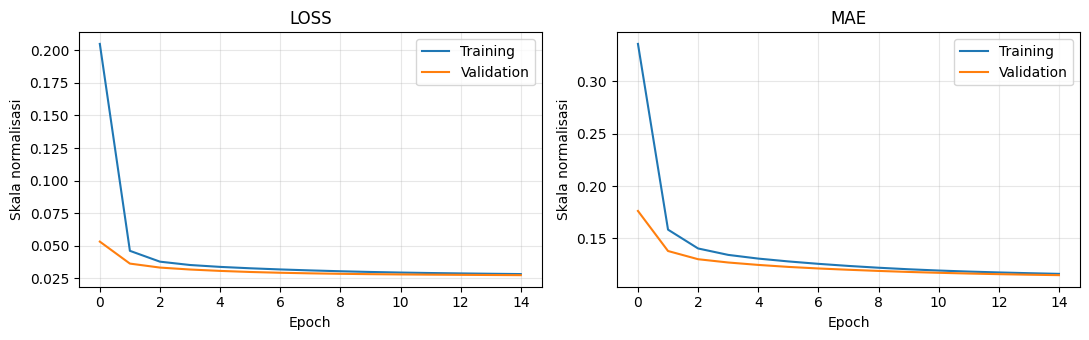

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for k, nama in enumerate(["loss", "mae"]):
    ax[k].plot(history.history[nama], label="Training")
    ax[k].plot(history.history["val_"+nama], label="Validation")
    ax[k].set(title=nama.upper(), xlabel="Epoch", ylabel="Skala normalisasi")
    ax[k].legend()
    ax[k].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 9 — Menguji model pada data testing
Mengembalikan prediksi ke **°C** memakai rata-rata dan standar deviasi suhu dari training. Kita bandingkan LSTM dengan **baseline persistence**: menggunakan suhu terakhir yang diamati sebagai prediksi 1 jam berikutnya. Model yang baik seharusnya berusaha mengalahkan baseline sederhana ini.

In [ ]:
pred_scaled = model.predict(X_test, verbose=0).ravel()
rerata_suhu, skala_suhu = scaler.mean_[0], scaler.scale_[0]
aktual = y_test*skala_suhu + rerata_suhu
prediksi = pred_scaled*skala_suhu + rerata_suhu
baseline = X_test[:, -1, 0]*skala_suhu + rerata_suhu

for nama, nilai in [("LSTM", prediksi), ("Baseline suhu terakhir", baseline)]:
    mae = mean_absolute_error(aktual, nilai)
    rmse = np.sqrt(mean_squared_error(aktual, nilai))
    print(f"{nama:23s} | MAE = {mae:.2f} °C | RMSE = {rmse:.2f} °C")

LSTM                    | MAE = 0.30 °C | RMSE = 0.43 °C
Baseline suhu terakhir  | MAE = 0.63 °C | RMSE = 0.77 °C


## Cell 10 — Grafik hasil testing
Grafik pertama membandingkan suhu aktual, prediksi LSTM, dan baseline selama 3 hari pada **data testing**. Grafik kedua menampilkan distribusi galat prediksi LSTM. Perhatikan kapan model sulit mengikuti perubahan suhu mendadak.

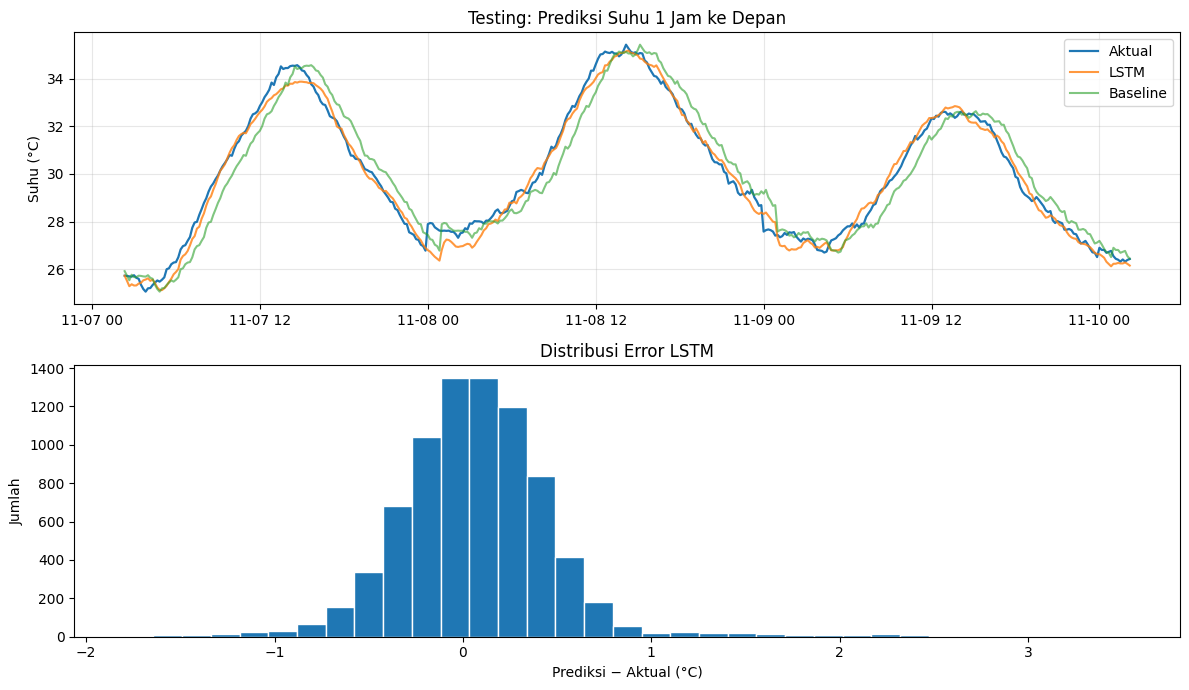

In [ ]:
jumlah = 3*24*6  # 3 hari = 432 titik
waktu = df.loc[i_test[:jumlah], "Date Time"]
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
ax[0].plot(waktu, aktual[:jumlah], label="Aktual", linewidth=1.6)
ax[0].plot(waktu, prediksi[:jumlah], label="LSTM", alpha=0.8)
ax[0].plot(waktu, baseline[:jumlah], label="Baseline", alpha=0.6)
ax[0].set(title="Testing: Prediksi Suhu 1 Jam ke Depan", ylabel="Suhu (°C)")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].hist(prediksi-aktual, bins=35, edgecolor="white")
ax[1].set(title="Distribusi Error LSTM", xlabel="Prediksi − Aktual (°C)", ylabel="Jumlah")
plt.tight_layout(); plt.show()

## Cell 11 — Prediksi berdasarkan 6 jam data terbaru
Memakai 36 baris terakhir untuk memperkirakan suhu **1 jam setelah catatan paling akhir**. Input harus dinormalisasi menggunakan scaler yang **sama seperti training**; jangan melakukan `fit` scaler baru.

In [ ]:
input_baru = X_all[-WINDOW:].reshape(1, WINDOW, len(FITUR))
hasil = model.predict(input_baru, verbose=0)[0, 0]*skala_suhu + rerata_suhu
waktu_target = df["Date Time"].iloc[-1] + pd.Timedelta(minutes=10*HORIZON)
print("Target waktu:", waktu_target)
print(f"Perkiraan suhu: {hasil:.2f} °C")

Target waktu: 2025-01-01 00:50:00
Perkiraan suhu: 26.95 °C


## Tugas mahasiswa — 5 eksperimen

**Petunjuk:** lakukan **satu perubahan saja setiap percobaan**, lalu jalankan ulang mulai dari cell model atau cell window. Catat **MAE testing (°C)** dan bandingkan dengan baseline. Jangan memakai data testing untuk memilih hyperparameter terbaik; gunakan hasil validation untuk memilih konfigurasi, lalu laporkan testing sekali pada konfigurasi final.

1. **Ukuran window:** ubah `WINDOW` dari `36` menjadi `12` (2 jam) atau `72` (12 jam). Apa pengaruhnya pada validation MAE?
2. **Jumlah neuron:** ganti `LSTM(16)` menjadi `LSTM(8)` dan `LSTM(32)`. Apakah model lebih besar pasti lebih baik?
3. **Learning rate:** uji `0.01`, `0.001`, dan `0.0001`. Mana yang paling stabil pada grafik loss?
4. **Batch size:** bandingkan `BATCH_SIZE=32` dan `128`. Bagaimana dampaknya pada waktu training dan validation MAE?
5. **Horizon prediksi:** ubah `HORIZON=6` menjadi `18` (3 jam). Apakah MAE meningkat? Mengapa prediksi jauh ke depan lebih sulit?

**Pertanyaan diskusi:** jika MAE LSTM lebih buruk daripada baseline, apakah LSTM layak digunakan? Mengapa *random train/test split* kurang tepat untuk data sekuensial?

**Sumber acuan iklim:** BPS, *DKI Jakarta Dalam Angka 2025*, Tabel 1.2.2 (data BMKG Kemayoran 2024). Dataset CSV ini adalah simulasi yang dikalibrasi secara kasar, **bukan** rekonstruksi atau data historis observasi.